# Dataset Loading & Understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

In [3]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [4]:
RANDOM_STATE = 42

In [5]:
filename = "city_lifestyle_dataset.csv"
df = pd.read_csv(filename)

In [6]:
df.head()

,city_name,country,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
0,Old Vista,Europe,2775,3850,86.4,1310,43,52.0,8.5,23.8
1,Beachport,Europe,3861,3700,78.1,1330,42,62.8,8.1,33.1
2,Valleyborough,Europe,2562,4310,80.1,1330,39,73.2,8.5,40.2
3,City,Europe,3192,3970,81.2,1480,60,49.2,8.5,43.6
4,Falls,Europe,3496,4320,100.0,1510,64,93.7,8.5,42.5


In [7]:
df.shape

(300, 10)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city_name               300 non-null    object 
 1   country                 300 non-null    object 
 2   population_density      300 non-null    int64  
 3   avg_income              300 non-null    int64  
 4   internet_penetration    300 non-null    float64
 5   avg_rent                300 non-null    int64  
 6   air_quality_index       300 non-null    int64  
 7   public_transport_score  300 non-null    float64
 8   happiness_score         300 non-null    float64
 9   green_space_ratio       300 non-null    float64
dtypes: float64(4), int64(4), object(2)
memory usage: 23.6+ KB


In [9]:
df.describe()

,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,3944.843333,2827.200000,74.305333,1002.766667,71.246667,55.717333,6.644000,33.993333
std,2982.566777,1201.163939,17.014492,456.282066,25.344961,14.712549,1.685864,9.434067
min,100.000000,480.000000,34.000000,170.000000,22.000000,15.000000,2.500000,2.000000
25%,1830.000000,1907.500000,64.400000,640.000000,54.000000,46.075000,5.300000,28.225000
50%,3083.500000,2810.000000,75.000000,990.000000,67.500000,54.700000,6.900000,34.700000
75%,4823.750000,3752.500000,87.225000,1332.500000,86.000000,64.200000,8.500000,40.400000
max,14427.000000,5720.000000,100.000000,2430.000000,146.000000,95.000000,8.500000,58.000000


In [10]:
df.isnull().sum()

,0
city_name,0
country,0
population_density,0
avg_income,0
internet_penetration,0
avg_rent,0
air_quality_index,0
public_transport_score,0
happiness_score,0
green_space_ratio,0


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.columns.tolist()

['city_name',
 'country',
 'population_density',
 'avg_income',
 'internet_penetration',
 'avg_rent',
 'air_quality_index',
 'public_transport_score',
 'happiness_score',
 'green_space_ratio']

In [13]:
features = [
    "population_density",
    "avg_income",
    "internet_penetration",
    "avg_rent",
    "air_quality_index",
    "public_transport_score",
    "happiness_score",
    "green_space_ratio"
]

In [14]:
X = df[features].copy()

In [15]:
for col in features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

In [16]:
X = X.fillna(X.median())

In [17]:
X.columns.tolist()

['population_density',
 'avg_income',
 'internet_penetration',
 'avg_rent',
 'air_quality_index',
 'public_transport_score',
 'happiness_score',
 'green_space_ratio']

In [18]:
X.isnull().sum()

,0
population_density,0
avg_income,0
internet_penetration,0
avg_rent,0
air_quality_index,0
public_transport_score,0
happiness_score,0
green_space_ratio,0


In [19]:
scaler = StandardScaler()

In [20]:
X_scaled = scaler.fit_transform(X)

In [21]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

In [23]:
X_scaled_df.head()

,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
0,-0.392882,0.852930,0.712033,0.674466,-1.116351,-0.253086,1.102759,-1.082287
1,-0.028158,0.727843,0.223398,0.718372,-1.155872,0.482207,0.865095,-0.094850
2,-0.464417,1.236532,0.341141,0.718372,-1.274437,1.190268,1.102759,0.658999
3,-0.252836,0.953000,0.405900,1.047665,-0.444485,-0.443718,1.102759,1.019997
4,-0.150740,1.244871,1.512687,1.113524,-0.286399,2.585965,1.102759,0.903203


In [24]:
X_scaled_df.mean().round(3)

,0
population_density,0.0
avg_income,0.0
internet_penetration,0.0
avg_rent,0.0
air_quality_index,-0.0
public_transport_score,0.0
happiness_score,-0.0
green_space_ratio,0.0


# Exploratory Data Analysis

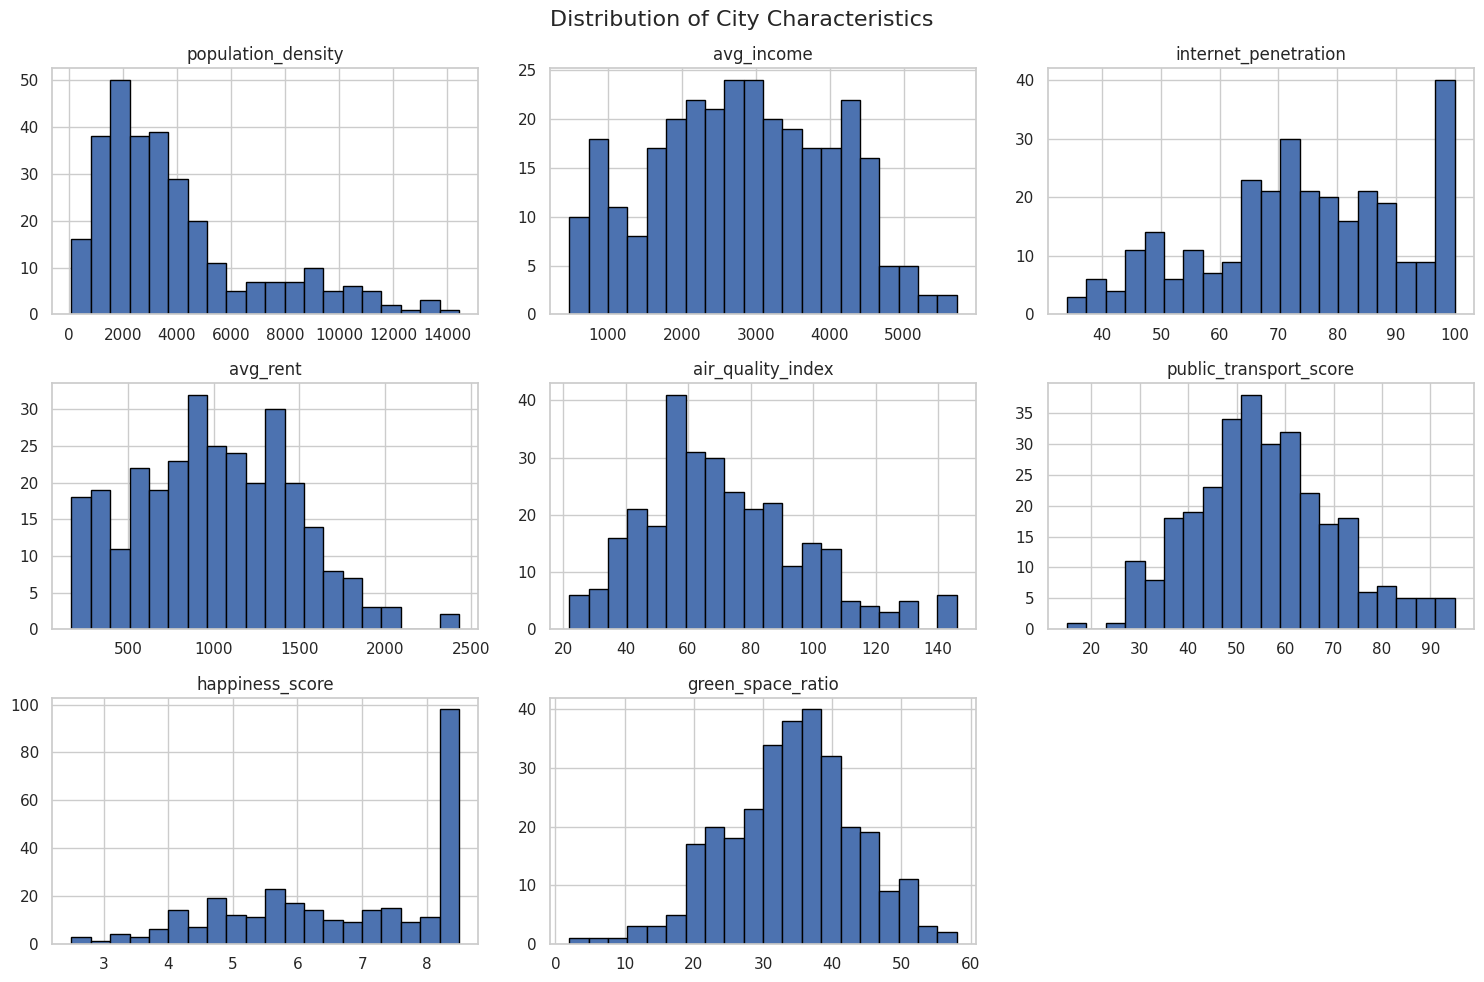

In [26]:
X.hist(
    bins=20,
    figsize=(15, 10),
    edgecolor="black"
)
plt.suptitle("Distribution of City Characteristics",fontsize=16)
plt.tight_layout()
plt.show()

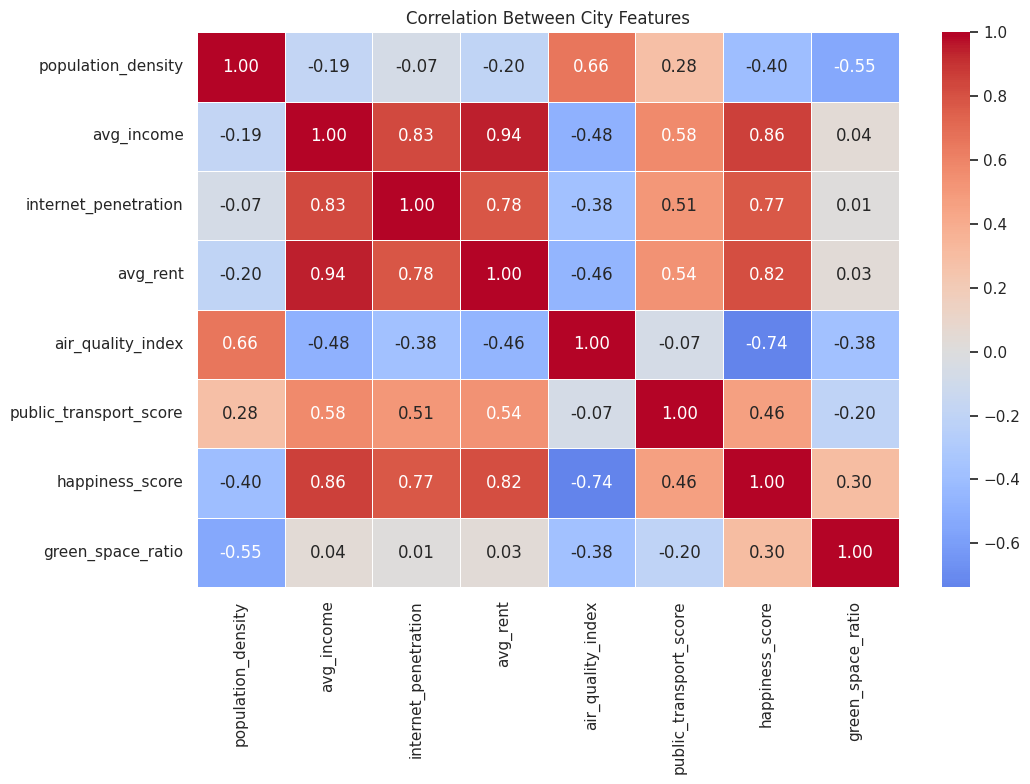

In [27]:
plt.figure(figsize=(11, 8))
sns.heatmap(X.corr(),annot=True,fmt=".2f",cmap="coolwarm",center=0,linewidths=0.5)
plt.title("Correlation Between City Features")
plt.tight_layout()
plt.show()

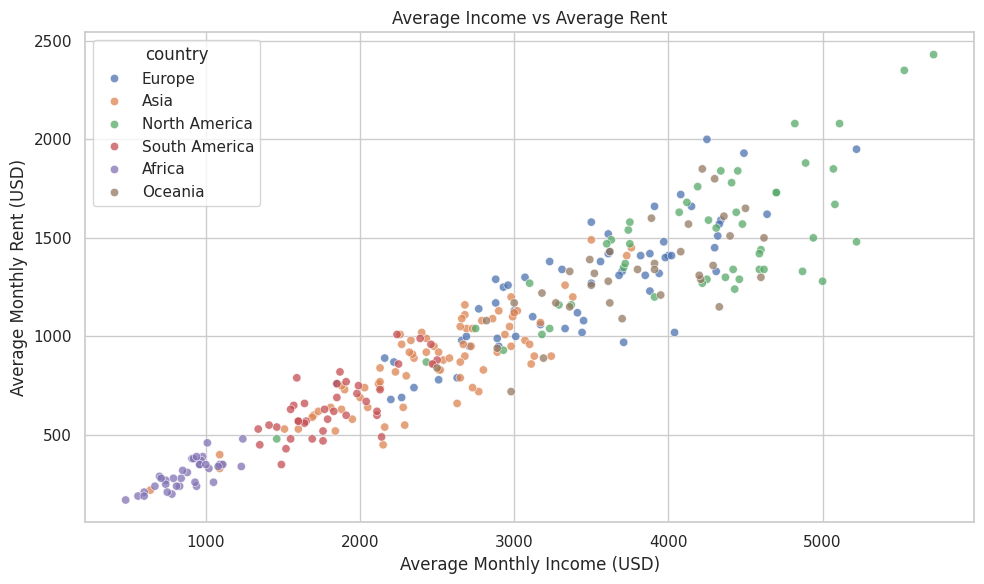

In [28]:

sns.scatterplot(
    data=df,
    x="avg_income",
    y="avg_rent",
    hue="country",
    alpha=0.75
)

plt.title("Average Income vs Average Rent")
plt.xlabel("Average Monthly Income (USD)")
plt.ylabel("Average Monthly Rent (USD)")
plt.tight_layout()
plt.show()


# Optimal Cluster Selection

In [29]:
k_values = range(2, 11)
inertias = []
silhouette_scores = []
for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

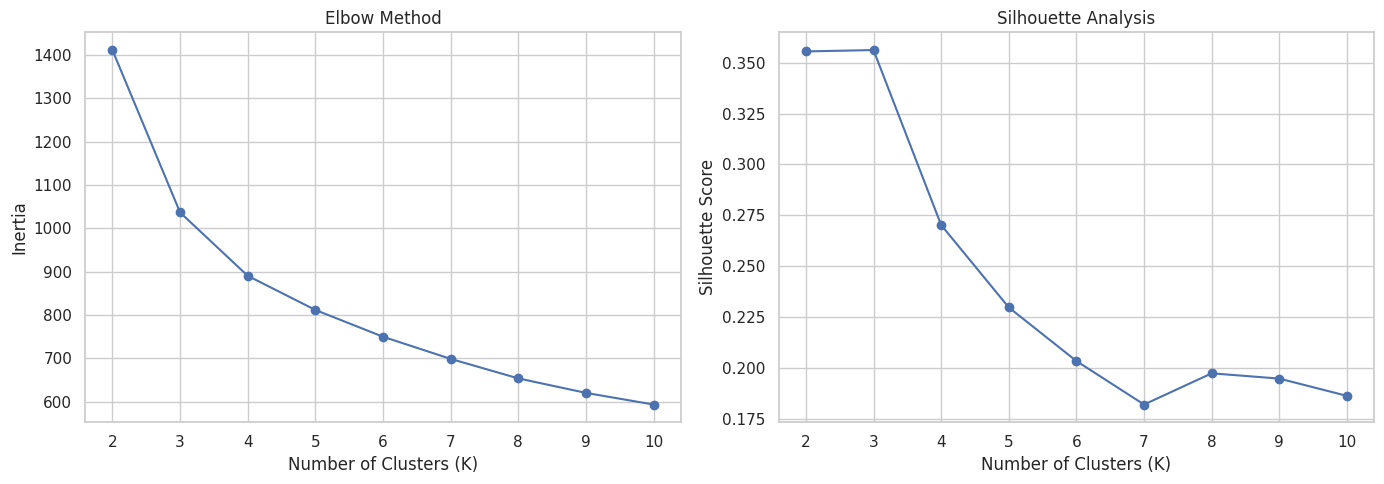

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    list(k_values),
    inertias,
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)
axes[1].set_title("Silhouette Analysis")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [31]:
optimal_k = list(k_values)[np.argmax(silhouette_scores)]

In [32]:
print("Best K by Silhouette Score:", optimal_k)
print("Best Silhouette Score:", max(silhouette_scores))

Best K by Silhouette Score: 3
Best Silhouette Score: 0.35620779965967825


In [33]:

evaluation_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(evaluation_df.round(4))


,K,Inertia,Silhouette Score
0,2,1411.0539,0.3555
1,3,1036.5915,0.3562
2,4,890.4332,0.2702
3,5,811.6959,0.2297
4,6,749.9310,0.2034
5,7,698.8734,0.1820
6,8,653.8664,0.1974
7,9,620.4237,0.1948
8,10,593.5624,0.1863


# K-Means Clustering & Visualization

In [34]:

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=RANDOM_STATE,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

print("\nFinal Silhouette Score:")
print(silhouette_score(
    X_scaled,
    df["Cluster"]
))

print("\nDavies-Bouldin Index:")
print(davies_bouldin_score(
    X_scaled,
    df["Cluster"]
))

Cluster Distribution:
Cluster
0     85
1    143
2     72
Name: count, dtype: int64

Final Silhouette Score:
0.35620779965967825

Davies-Bouldin Index:
1.1026847106478908


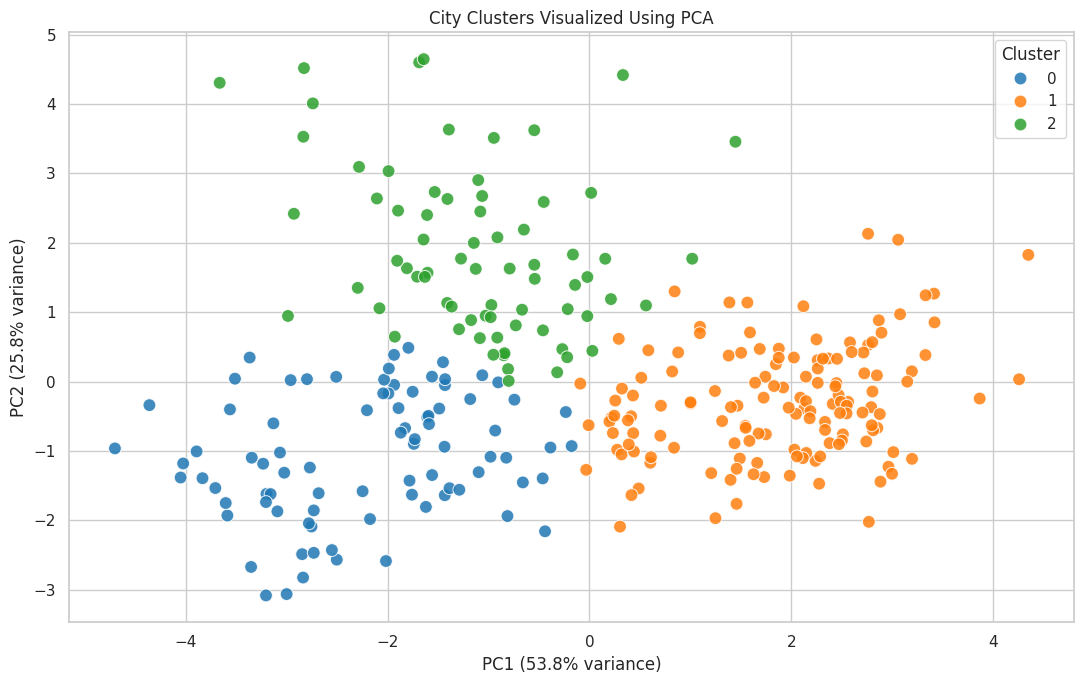

Total Variance Explained: 0.7964


In [35]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=85,
    alpha=0.85
)

plt.title("City Clusters Visualized Using PCA")
plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)"
)

plt.tight_layout()
plt.show()

print(
    "Total Variance Explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

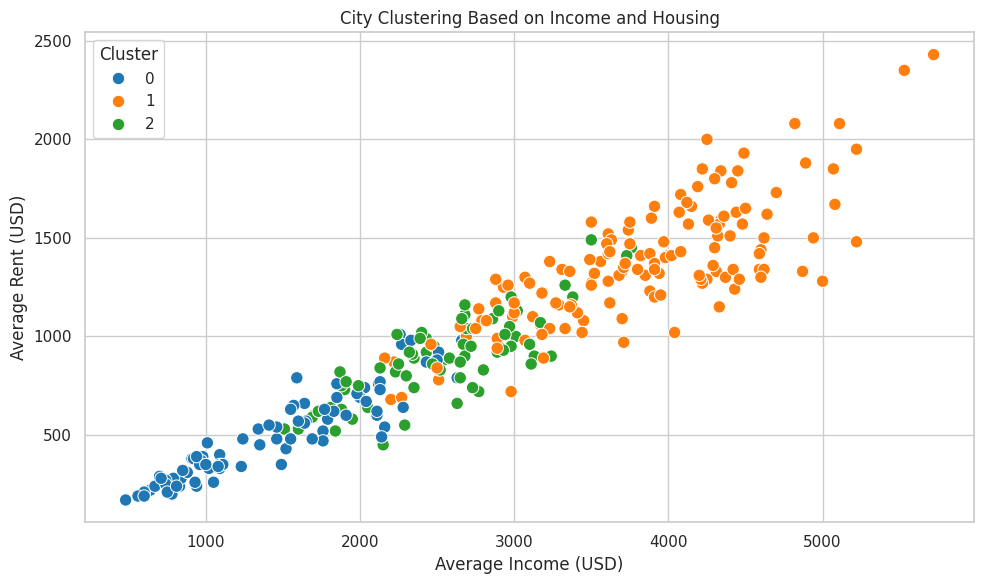

In [36]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="avg_income",
    y="avg_rent",
    hue="Cluster",
    palette="tab10",
    s=80
)

plt.title("City Clustering Based on Income and Housing")
plt.xlabel("Average Income (USD)")
plt.ylabel("Average Rent (USD)")
plt.tight_layout()
plt.show()


Average Characteristics of Each Cluster:


,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
Cluster,,,,,,,,
0,2991.33,1434.00,55.30,495.41,78.52,40.99,4.97,36.03
1,2367.34,3804.06,86.26,1361.54,53.76,60.76,8.15,37.08
2,8203.62,2531.81,73.00,889.17,97.39,63.09,5.63,25.46


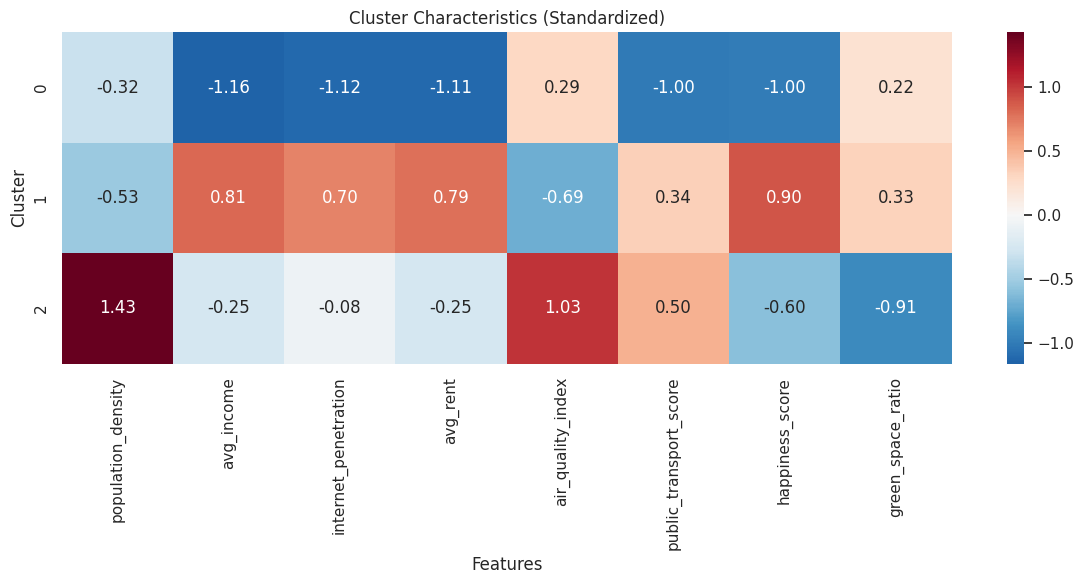

In [37]:

cluster_profiles = df.groupby("Cluster")[features].mean()

print("Average Characteristics of Each Cluster:")
display(cluster_profiles.round(2))

plt.figure(figsize=(12, 6))

# Standardize cluster averages for comparison
scaled_profiles = X_scaled_df.copy()
scaled_profiles["Cluster"] = df["Cluster"].values

profile_means = scaled_profiles.groupby("Cluster").mean()

sns.heatmap(
    profile_means,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("Cluster Characteristics (Standardized)")
plt.xlabel("Features")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


In [38]:
for cluster in sorted(df["Cluster"].unique()):
    print(f"\n{'='*40}")
    print(f"CLUSTER {cluster}")
    print(f"{'='*40}")

    subset = df[df["Cluster"] == cluster]

    print("Number of Cities:", len(subset))

    display(
        subset[
            ["city_name", "country", "avg_income",
             "avg_rent", "Cluster"]
        ].head(10)
    )


CLUSTER 0
Number of Cities: 85


,city_name,country,avg_income,avg_rent,Cluster
13,Bridge,Europe,2660,980,0
23,Harborshire,Europe,1850,760,0
56,Harborport,Europe,2630,790,0
65,Gardenborough,Asia,2260,1010,0
70,Old Wood,Asia,640,220,0
71,Old Springs,Asia,2270,960,0
78,Park,Asia,1090,330,0
101,Hilldale,Asia,2030,740,0
104,Bridgeburg,Asia,2000,690,0
105,Mount Falls,Asia,2330,980,0



CLUSTER 1
Number of Cities: 143


,city_name,country,avg_income,avg_rent,Cluster
0,Old Vista,Europe,3850,1310,1
1,Beachport,Europe,3700,1330,1
2,Valleyborough,Europe,4310,1330,1
3,City,Europe,3970,1480,1
4,Falls,Europe,4320,1510,1
5,North Falls,Europe,4640,1620,1
6,Hillhaven,Europe,3450,1080,1
7,Gardenton,Europe,3610,1520,1
8,Springsville,Europe,5220,1950,1
9,North Ridge,Europe,3330,1040,1



CLUSTER 2
Number of Cities: 72


,city_name,country,avg_income,avg_rent,Cluster
27,Woodshire,Europe,2350,740,2
36,Forestshire,Europe,3010,1000,2
61,Forestdale,Asia,1840,520,2
62,Woodburg,Asia,1510,530,2
63,North City,Asia,2770,720,2
64,Riverford,Asia,3170,1070,2
66,San Point,Asia,2690,1040,2
67,Saint Forest,Asia,1700,600,2
68,Bay,Asia,2510,830,2
69,Mount Ridge,Asia,3500,1490,2


In [39]:
output_df = df.drop(columns=["PC1", "PC2"])

output_df.to_csv(
    "city_area_clustering_results.csv",
    index=False
)

print("Results saved successfully!")

from google.colab import files
files.download("city_area_clustering_results.csv")

Results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>